Mean of X: 5.0
Mean of Y: 13.0

Deviation Table:
 X  Y  X - X_mean  Y - Y_mean  (X - X_mean)^2  (X - X_mean)(Y - Y_mean)
 1  5        -4.0        -8.0            16.0                      32.0
 2  7        -3.0        -6.0             9.0                      18.0
 3  9        -2.0        -4.0             4.0                       8.0
 4 11        -1.0        -2.0             1.0                       2.0
 5 13         0.0         0.0             0.0                       0.0
 6 15         1.0         2.0             1.0                       2.0
 7 17         2.0         4.0             4.0                       8.0
 8 19         3.0         6.0             9.0                      18.0
 9 21         4.0         8.0            16.0                      32.0

OLS Calculations:
Slope (m): 2.0
Intercept (c): 3.0
Regression Equation: Y = 2.00X + 3.00

Sklearn OLS Results:
Slope: 2.0000000000000004
Intercept: 2.9999999999999982
Training MSE: 7.888609052210118e-31

Actual vs Predicted:
 X  

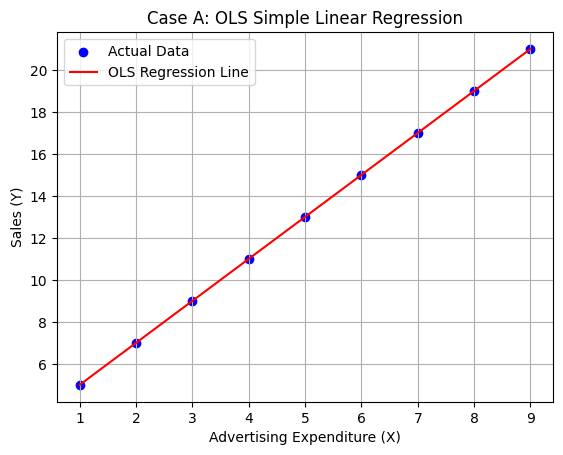


Conclusion:
The relationship is perfectly linear.
The OLS equation is Y = 2X + 3.
Training MSE is 0.
OLS is sufficient for this clean dataset.
Ridge and Lasso regularization are not necessary here.


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

X = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9]).reshape(-1, 1)
Y = np.array([5, 7, 9, 11, 13, 15, 17, 19, 21])

x_mean = X.mean()
y_mean = Y.mean()

print("Mean of X:", x_mean)
print("Mean of Y:", y_mean)

x_dev = X.flatten() - x_mean
y_dev = Y - y_mean

x_dev_sq = x_dev ** 2
xy_dev = x_dev * y_dev

table = pd.DataFrame({
    "X": X.flatten(),
    "Y": Y,
    "X - X_mean": x_dev,
    "Y - Y_mean": y_dev,
    "(X - X_mean)^2": x_dev_sq,
    "(X - X_mean)(Y - Y_mean)": xy_dev
})

print("\nDeviation Table:")
print(table.to_string(index=False))

m = np.sum(xy_dev) / np.sum(x_dev_sq)
c = y_mean - m * x_mean

print("\nOLS Calculations:")
print("Slope (m):", m)
print("Intercept (c):", c)
print(f"Regression Equation: Y = {m:.2f}X + {c:.2f}")

model = LinearRegression()
model.fit(X, Y)

Y_pred = model.predict(X)

print("\nSklearn OLS Results:")
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

mse = mean_squared_error(Y, Y_pred)

print("Training MSE:", mse)

results = pd.DataFrame({
    "X": X.flatten(),
    "Actual Y": Y,
    "Predicted Y": Y_pred,
    "Error": Y - Y_pred
})

print("\nActual vs Predicted:")
print(results.to_string(index=False))

plt.scatter(X, Y, color="blue", label="Actual Data")
plt.plot(X, Y_pred, color="red", label="OLS Regression Line")
plt.xlabel("Advertising Expenditure (X)")
plt.ylabel("Sales (Y)")
plt.title("Case A: OLS Simple Linear Regression")
plt.legend()
plt.grid(True)
plt.show()

print("\nConclusion:")
print("The relationship is perfectly linear.")
print("The OLS equation is Y = 2X + 3.")
print("Training MSE is 0.")
print("OLS is sufficient for this clean dataset.")
print("Ridge and Lasso regularization are not necessary here.")